In [3]:
import copy
import random

import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn

from torch.utils.data import DataLoader, TensorDataset

plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 16,
    "font.family": "Times New Roman",
})

# 1. Подготовка данных

In [ ]:
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError("Запустите ноутбук из папки lab8 или lab8/notebooks.")

Параметры для обучения

In [ ]:
SEED            = 42
BATCH_SIZE      = 32
HIDDEN_SIZE     = 32
LEARNING_RATE   = 0.001
WEIGHT_DECAY    = 0.0001
MAX_EPOCHS      = 120
PATIENCE        = 15

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

device = torch.device("cpu")
# device = torch.device("cuda")

In [6]:
required_files = ["prepared.npz", "preprocessing.json", "observations.csv"]

for name in required_files:
    if not (ARTIFACTS_DIR / name).is_file():
        raise FileNotFoundError(f"Нет файла {name}!")
    
meta = json.loads((ARTIFACTS_DIR / 'preprocessing.json').read_text(encoding='utf-8'))

with np.load(ARTIFACTS_DIR / 'prepared.npz', allow_pickle=False) as data:
    X_train, y_train = data['X_train'].copy(), data['y_train'].copy()
    X_val, y_val = data['X_val'].copy(), data['y_val'].copy()
    val_dates = pd.to_datetime(data['dates_val'])

data_hashes = {
    name: hashlib.sha256((ARTIFACTS_DIR / name).read_bytes()).hexdigest()
    for name in ["prepared.npz", "preprocessing.json", "observations.csv"]
}

# for X, y in [(X_train, y_train), (X_val, y_val)]:
#     assert X.ndim == 3 and y.ndim == 1
#     assert len(X) == len(y) and len(X) > 0
#     assert X.shape[1:] == (meta["lookback"], len(meta["features"]))
#     assert np.isfinite(X).all() and np.isfinite(y).all()
    
print( "Train:", X_train.shape )
print( "Validation:", X_val.shape )

Train: (701, 30, 6)
Validation: (365, 30, 6)


Порядок дней внутри окна сохраняется. Перемешиваются только обучающие окна.


In [8]:
train_x = torch.from_numpy(X_train)
train_y = torch.from_numpy(y_train)
train_dataset = TensorDataset(train_x, train_y)

generator = torch.Generator().manual_seed(SEED)

loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0,
)

val_x = torch.from_numpy(X_val).to(device)
val_y = torch.from_numpy(y_val).to(device)

print('PyTorch:', torch.__version__, '| Устройство:', device)

PyTorch: 2.14.1+cpu | Устройство: cpu


## 2. Модель

Однослойная LSTM → линейный одномерный слой → температура следующего дня.

Вход: `(batch, 30, 6)`. Выход: `(batch)`

In [9]:
class WeatherLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=32):
        
        super().__init__()
        self.lstm = nn.LSTM(input_size, 
                            hidden_size, 
                            num_layers=1, 
                            batch_first=True
                            )
        
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence, _ = self.lstm(x)
        return self.head(sequence[:, -1, :]).squeeze(-1)

config = {'input_size': X_train.shape[2], 'hidden_size': HIDDEN_SIZE}
model = WeatherLSTM(**config).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
loss_fn = nn.MSELoss()

print(model)
print('Обучаемых параметров:', sum(p.numel() for p in model.parameters()))

WeatherLSTM(
  (lstm): LSTM(6, 32, batch_first=True)
  (head): Linear(in_features=32, out_features=1, bias=True)
)
Обучаемых параметров: 5153


## 3. Обучение

- MSE считается в стандартизованной шкале;
- Оптимизатор — Adam;
- Сохраняем веса лучшей эпохи по validation MSE; 
- Остановка — после 15 эпох без улучшения.

In [10]:
best_loss, best_epoch, stale = float('inf'), 0, 0
history, best_state = [], None

for epoch in range(1, MAX_EPOCHS + 1):
    
    model.train()
    total = 0.0
    
    # Обучение
    for batch_x, batch_y in loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        # Оптимизатор
        optimizer.zero_grad(set_to_none=True)
        
        # Loss
        loss = loss_fn(model(batch_x), batch_y)
        
        # Backprop
        loss.backward()
        # Нормализация градиента
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total += loss.item() * len(batch_x)
        
    model.eval()
    
    # Валидация
    with torch.no_grad():
        val_loss = loss_fn(model(val_x), val_y).item()
        
    history.append({'epoch': epoch, 'train_mse_scaled': total / len(X_train),
                    'val_mse_scaled': val_loss})
    
    if not np.isfinite(val_loss) or not np.isfinite(total):
        raise RuntimeError('Обучение расходится: validation loss не конечен')
    
    # Сохраняем лучшую точность (ломаем цикл после PATIENCE циклов)
    if val_loss < best_loss - 1e-6:
        best_loss, best_epoch = val_loss, epoch
        best_state = copy.deepcopy(model.state_dict())
        stale = 0
    else:
        stale += 1
    if epoch == 1 or epoch % 10 == 0:
        print(f'Эпоха {epoch:3d}: train={total / len(X_train):.4f}, val={val_loss:.4f}')
    if stale >= PATIENCE:
        print('Ранняя остановка')
        break

assert best_state is not None
model.load_state_dict(best_state)
history = pd.DataFrame(history)

Эпоха   1: train=0.7997, val=0.5827
Эпоха  10: train=0.1596, val=0.1692
Эпоха  20: train=0.1305, val=0.1415
Эпоха  30: train=0.1179, val=0.1313
Эпоха  40: train=0.1094, val=0.1311
Эпоха  50: train=0.1039, val=0.1333
Ранняя остановка


Кривые обучения

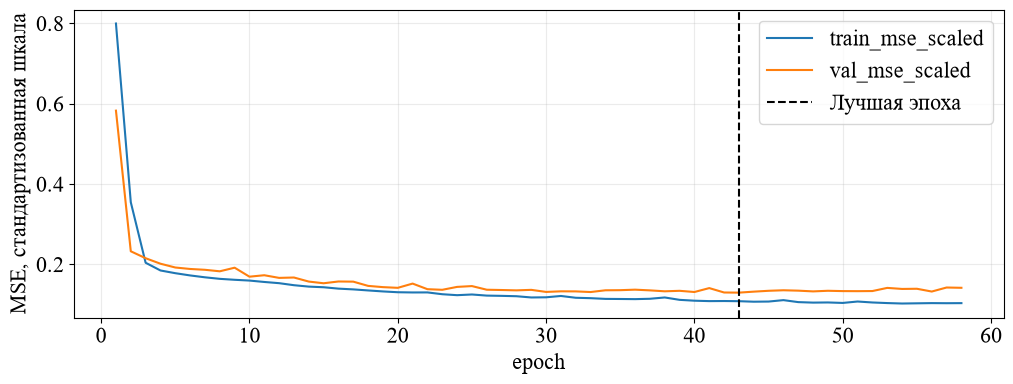

Лучшая эпоха: 43


In [11]:
history.plot(x='epoch', y=['train_mse_scaled', 'val_mse_scaled'])

plt.axvline(best_epoch, color='black', linestyle='--', label='Лучшая эпоха')
plt.ylabel('MSE, стандартизованная шкала')
plt.legend()
plt.show()
print('Лучшая эпоха:', best_epoch)

## 4. Сравнение на validation

- `persistence` — температура предыдущего дня. 
- `mean_7` — среднее прошлых семи дней.
- `seasonal` — годовая синусоида, подобранная на train.
- Модель выбирается по минимальному RMSE на validation.

In [14]:
observations = pd.read_csv(ARTIFACTS_DIR / 'observations.csv', parse_dates=['date']).set_index('date')

# Коэффициенты сезонного прогноза оцениваем на train.
def seasonal_design(index):
    angle = 2 * np.pi * (index.dayofyear - 1) / np.where(index.is_leap_year, 366, 365)
    return np.column_stack([np.ones(len(index)), np.sin(angle), np.cos(angle)])

train_obs = observations.loc[observations.index < pd.Timestamp(meta['train_end_exclusive'])]

coef = np.linalg.lstsq(seasonal_design(train_obs.index), train_obs.temp_max.to_numpy(), rcond=None)[0]

model.eval()

with torch.no_grad():
    
    pred = model(val_x).cpu().numpy() * meta['y_std'] + meta['y_mean']
truth = y_val * meta['y_std'] + meta['y_mean']

val_predictions = pd.DataFrame({
    'actual': truth, 'lstm': pred,
    'persistence': observations.temp_max.shift(1).reindex(val_dates).to_numpy(),
    'mean_7': observations.temp_max.shift(1).rolling(7).mean().reindex(val_dates).to_numpy(),
    'seasonal': seasonal_design(val_dates) @ coef}, index=val_dates)

val_scores = pd.DataFrame({name: {
    'MAE_C': np.mean(np.abs(val_predictions[name] - truth)),
    'RMSE_C': np.sqrt(np.mean((val_predictions[name] - truth)**2))
} for name in ['lstm', 'persistence', 'mean_7', 'seasonal']}).T.sort_values('RMSE_C')

display(val_scores.round(3))

,MAE_C,RMSE_C
lstm,2.103,2.636
persistence,2.276,2.955
mean_7,2.894,3.683
seasonal,2.986,3.821


## 5. Сохранение результатов

- `lstm.pt` — лучшие веса и конфигурация;
- `training_history.csv` — история обучения;
- `validation_predictions.csv` и `validation_metrics.csv` — результаты на validation;
- `seasonal_coef.npy` — коэффициенты сезонного прогноза;
- `selection.json` — выбор модели и настройки.

Повторный запуск заменяет эти файлы.

In [ ]:
torch.save({'state_dict': best_state, 'data_hashes': data_hashes, 'config': config, 'best_epoch': best_epoch,
            'raw_sha256': meta['raw_sha256'], 'features': meta['features'],
            'lookback': meta['lookback'], 'y_mean': meta['y_mean'], 'y_std': meta['y_std']},
           ARTIFACTS_DIR / 'lstm.pt')
np.save(ARTIFACTS_DIR / 'seasonal_coef.npy', coef)
val_predictions.to_csv(ARTIFACTS_DIR / 'validation_predictions.csv', index_label='date')
val_scores.to_csv(ARTIFACTS_DIR / 'validation_metrics.csv', index_label='model')
(ARTIFACTS_DIR / 'selection.json').write_text(json.dumps({
    'selected_by_validation_rmse': selected, 'data_hashes': data_hashes, 'seed': SEED,
    'best_epoch': best_epoch, 'torch_version': str(torch.__version__),
    'numpy_version': np.__version__, 'pandas_version': pd.__version__,
    'config': config, 'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY,
    'max_epochs': MAX_EPOCHS, 'patience': PATIENCE,
}, indent=2), encoding='utf-8')

history.to_csv(ARTIFACTS_DIR / "training_history.csv", index=False)